# **Environment Setup and Seed Locking**

In [ ]:
import os
import torch
import numpy as np
import random
from google.colab import drive

# 1. Mount Google Drive for persistent storage
drive.mount('/content/drive')
save_dir = '/content/drive/MyDrive/AgriVision_Efficient_Research'
os.makedirs(save_dir, exist_ok=True)

# 2. Enforce Strict Reproducibility
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

print(f"Drive mounted at {save_dir}. Random seeds locked to {SEED} for reproducibility.")

Mounted at /content/drive
Drive mounted at /content/drive/MyDrive/AgriVision_Efficient_Research. Random seeds locked to 42 for reproducibility.


# **Dataset Acquisition**

In [ ]:
from google.colab import files
import os

# Upload kaggle.json
print("Please upload your kaggle.json file:")
files.upload()

# Setup Kaggle secure folder
os.makedirs('/root/.kaggle', exist_ok=True)
!cp kaggle.json /root/.kaggle/
!chmod 600 /root/.kaggle/kaggle.json

# Download and extract
print("Downloading dataset...")
!kaggle datasets download -d vipoooool/new-plant-diseases-dataset
!unzip -q new-plant-diseases-dataset.zip -d Massive_Plant_Data
print("Dataset successfully extracted!")

Please upload your kaggle.json file:


Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/vipoooool/new-plant-diseases-dataset
License(s): copyright-authors
100% 2.70G/2.70G [02:42<00:00, 17.8MB/s]

Dataset successfully extracted!


# **The Reproducible Data Loader**

In [ ]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset

data_dir = '/content/Massive_Plant_Data/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/train'

# Training transforms (Heavy augmentation)
train_transforms = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(45),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Validation transforms (Clean standardization)
val_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Create two independent dataset objects pointing to the same folder
train_base = datasets.ImageFolder(root=data_dir, transform=train_transforms)
val_base = datasets.ImageFolder(root=data_dir, transform=val_transforms)

# Generate deterministic index split using the locked seed
indices = list(range(len(train_base)))
np.random.shuffle(indices)

split_point = int(0.8 * len(indices))
train_idx, val_idx = indices[:split_point], indices[split_point:]

# Apply the split
train_dataset = Subset(train_base, train_idx)
val_dataset = Subset(val_base, val_idx)

# Create active streams
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2, pin_memory=True)

class_names = train_base.classes
print(f"Reproducible split complete: {len(train_dataset)} training images, {len(val_dataset)} validation images.")
print(f"Classes: {len(class_names)}")

Reproducible split complete: 56236 training images, 14059 validation images.
Classes: 38


# **Build and Train the Reproducible ResNet-50 Baseline**

In [ ]:
import time
import copy
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models

# 0. Define the Hardware Device (CRITICAL FIX)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Hardware utilized: {device}")

# 1. Build the Architecture
print("Downloading ResNet-50...")
model_resnet = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)

# Freeze early layers to speed up training
for param in model_resnet.parameters():
    param.requires_grad = False

# Map final layer to our 38 classes
num_features = model_resnet.fc.in_features
model_resnet.fc = nn.Linear(num_features, len(class_names))
model_resnet = model_resnet.to(device)

# 2. Setup the Rules
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_resnet.fc.parameters(), lr=0.001)

# 3. The Optimized Training Engine
def train_model(model, criterion, optimizer, model_name, num_epochs=25, patience=5):
    start_time = time.time()
    best_model_wts = copy.deepcopy(model.state_dict())
    best_acc = 0.0
    epochs_no_improve = 0
    save_path = f"{save_dir}/{model_name}.pth"

    for epoch in range(num_epochs):
        print(f'\nEpoch {epoch+1}/{num_epochs}')
        print('-' * 10)

        for phase in ['train', 'val']:
            if phase == 'train':
                model.train()
                dataloader = train_loader
            else:
                model.eval()
                dataloader = val_loader

            running_loss = 0.0
            running_corrects = 0

            for inputs, labels in dataloader:
                inputs, labels = inputs.to(device), labels.to(device)
                optimizer.zero_grad()

                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    _, preds = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)

                    if phase == 'train':
                        loss.backward()
                        optimizer.step()

                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)

            epoch_loss = running_loss / len(dataloader.dataset)
            epoch_acc = running_corrects.double() / len(dataloader.dataset)

            print(f'{phase.capitalize()} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}')

            if phase == 'val':
                if epoch_acc > best_acc:
                    best_acc = epoch_acc
                    best_model_wts = copy.deepcopy(model.state_dict())
                    epochs_no_improve = 0
                    # Save directly to Google Drive
                    torch.save(model.state_dict(), save_path)
                    print(f">>> New Best Model Saved to Drive! (Acc: {best_acc:.4f})")
                else:
                    epochs_no_improve += 1
                    print(f"--> No improvement. Early stopping counter: {epochs_no_improve}/{patience}")

        if epochs_no_improve >= patience:
            print(f"\nEarly stopping triggered! Accuracy flatlined for {patience} epochs.")
            break

    time_elapsed = time.time() - start_time
    print(f'\nTraining complete in {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s')
    print(f'Best Validation Accuracy: {best_acc:.4f}')

    model.load_state_dict(best_model_wts)
    return model

# 4. START TRAINING
print("\nStarting ResNet-50 Training...")
trained_resnet = train_model(model_resnet, criterion, optimizer, "resnet50_baseline")

Hardware utilized: cuda

Starting ResNet-50 Training...

Epoch 1/25
----------
Train Loss: 0.7836 Acc: 0.8535
Val Loss: 0.3789 Acc: 0.9185
>>> New Best Model Saved to Drive! (Acc: 0.9185)

Epoch 2/25
----------
Train Loss: 0.2846 Acc: 0.9313
Val Loss: 0.2581 Acc: 0.9379
>>> New Best Model Saved to Drive! (Acc: 0.9379)

Epoch 3/25
----------
Train Loss: 0.2168 Acc: 0.9416
Val Loss: 0.2052 Acc: 0.9494
>>> New Best Model Saved to Drive! (Acc: 0.9494)

Epoch 4/25
----------
Train Loss: 0.1868 Acc: 0.9478
Val Loss: 0.1770 Acc: 0.9511
>>> New Best Model Saved to Drive! (Acc: 0.9511)

Epoch 5/25
----------
Train Loss: 0.1663 Acc: 0.9512
Val Loss: 0.1657 Acc: 0.9543
>>> New Best Model Saved to Drive! (Acc: 0.9543)

Epoch 6/25
----------
Train Loss: 0.1529 Acc: 0.9549
Val Loss: 0.1491 Acc: 0.9582
>>> New Best Model Saved to Drive! (Acc: 0.9582)

Epoch 7/25
----------
Train Loss: 0.1451 Acc: 0.9565
Val Loss: 0.1367 Acc: 0.9587
>>> New Best Model Saved to Drive! (Acc: 0.9587)

Epoch 8/25
--------

# **Define the Training Engine**

In [ ]:
import time
import copy
import torch.nn as nn
import torch.optim as optim
from torchvision import models

criterion = nn.CrossEntropyLoss()

def train_model(model, criterion, optimizer, model_name, num_epochs=25, patience=5):
    start_time = time.time()
    best_model_wts = copy.deepcopy(model.state_dict())
    best_acc = 0.0
    epochs_no_improve = 0
    save_path = f"{save_dir}/{model_name}.pth"

    for epoch in range(num_epochs):
        print(f'\nEpoch {epoch+1}/{num_epochs}')
        print('-' * 10)

        for phase in ['train', 'val']:
            if phase == 'train':
                model.train()
                dataloader = train_loader
            else:
                model.eval()
                dataloader = val_loader

            running_loss = 0.0
            running_corrects = 0

            for inputs, labels in dataloader:
                inputs, labels = inputs.to(device), labels.to(device)
                optimizer.zero_grad()

                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    _, preds = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)

                    if phase == 'train':
                        loss.backward()
                        optimizer.step()

                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)

            epoch_loss = running_loss / len(dataloader.dataset)
            epoch_acc = running_corrects.double() / len(dataloader.dataset)
            print(f'{phase.capitalize()} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}')

            if phase == 'val':
                if epoch_acc > best_acc:
                    best_acc = epoch_acc
                    best_model_wts = copy.deepcopy(model.state_dict())
                    epochs_no_improve = 0
                    torch.save(model.state_dict(), save_path)
                    print(f">>> New Best Model Saved to Drive! (Acc: {best_acc:.4f})")
                else:
                    epochs_no_improve += 1
                    print(f"--> No improvement. Early stopping counter: {epochs_no_improve}/{patience}")

        if epochs_no_improve >= patience:
            print(f"\nEarly stopping triggered! Accuracy flatlined for {patience} epochs.")
            break

    time_elapsed = time.time() - start_time
    print(f'\n{model_name} Training complete in {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s')
    print(f'Best Validation Accuracy: {best_acc:.4f}')

    model.load_state_dict(best_model_wts)
    return model

# **Train MobileNetV2 and EfficientNet-B0**

In [ ]:
# 0. Define the Hardware Device (CRITICAL FIX)
import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Hardware utilized: {device}")

# --- 1. Train MobileNetV2 ---
print("Downloading MobileNetV2...")
mobilenet = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)

for param in mobilenet.parameters():
    param.requires_grad = False

in_features_mb = mobilenet.classifier[1].in_features
mobilenet.classifier[1] = nn.Linear(in_features_mb, len(class_names))
mobilenet = mobilenet.to(device)

opt_mobilenet = optim.Adam(mobilenet.classifier[1].parameters(), lr=0.001)
print("\nStarting MobileNetV2 Training...")
trained_mobilenet = train_model(mobilenet, criterion, opt_mobilenet, "mobilenet_v2_baseline")


# --- 2. Train EfficientNet-B0 ---
print("\nDownloading EfficientNet-B0...")
efficientnet = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)

for param in efficientnet.parameters():
    param.requires_grad = False

in_features_eff = efficientnet.classifier[1].in_features
efficientnet.classifier[1] = nn.Linear(in_features_eff, len(class_names))
efficientnet = efficientnet.to(device)

opt_efficientnet = optim.Adam(efficientnet.classifier[1].parameters(), lr=0.001)
print("\nStarting EfficientNet-B0 Training...")
trained_efficientnet = train_model(efficientnet, criterion, opt_efficientnet, "efficientnet_b0_baseline")

Hardware utilized: cuda

Starting MobileNetV2 Training...

Epoch 1/25
----------
Train Loss: 0.8294 Acc: 0.8165
Val Loss: 0.3396 Acc: 0.9136
>>> New Best Model Saved to Drive! (Acc: 0.9136)

Epoch 2/25
----------
Train Loss: 0.3967 Acc: 0.8863
Val Loss: 0.2635 Acc: 0.9245
>>> New Best Model Saved to Drive! (Acc: 0.9245)

Epoch 3/25
----------
Train Loss: 0.3353 Acc: 0.8980
Val Loss: 0.2172 Acc: 0.9374
>>> New Best Model Saved to Drive! (Acc: 0.9374)

Epoch 4/25
----------
Train Loss: 0.3154 Acc: 0.9006
Val Loss: 0.1973 Acc: 0.9406
>>> New Best Model Saved to Drive! (Acc: 0.9406)

Epoch 5/25
----------
Train Loss: 0.2997 Acc: 0.9046
Val Loss: 0.1854 Acc: 0.9426
>>> New Best Model Saved to Drive! (Acc: 0.9426)

Epoch 6/25
----------
Train Loss: 0.2907 Acc: 0.9068
Val Loss: 0.2133 Acc: 0.9309
--> No improvement. Early stopping counter: 1/5

Epoch 7/25
----------
Train Loss: 0.2845 Acc: 0.9072
Val Loss: 0.1771 Acc: 0.9426
--> No improvement. Early stopping counter: 2/5

Epoch 8/25
--------

100%|██████████| 20.5M/20.5M [00:00<00:00, 157MB/s]



Starting EfficientNet-B0 Training...

Epoch 1/25
----------
Train Loss: 0.7461 Acc: 0.8248
Val Loss: 0.2790 Acc: 0.9242
>>> New Best Model Saved to Drive! (Acc: 0.9242)

Epoch 2/25
----------
Train Loss: 0.3871 Acc: 0.8853
Val Loss: 0.2192 Acc: 0.9333
>>> New Best Model Saved to Drive! (Acc: 0.9333)

Epoch 3/25
----------
Train Loss: 0.3441 Acc: 0.8939
Val Loss: 0.2065 Acc: 0.9349
>>> New Best Model Saved to Drive! (Acc: 0.9349)

Epoch 4/25
----------
Train Loss: 0.3297 Acc: 0.8941
Val Loss: 0.1958 Acc: 0.9351
>>> New Best Model Saved to Drive! (Acc: 0.9351)

Epoch 5/25
----------
Train Loss: 0.3113 Acc: 0.9004
Val Loss: 0.1793 Acc: 0.9432
>>> New Best Model Saved to Drive! (Acc: 0.9432)

Epoch 6/25
----------
Train Loss: 0.3026 Acc: 0.9023
Val Loss: 0.1648 Acc: 0.9474
>>> New Best Model Saved to Drive! (Acc: 0.9474)

Epoch 7/25
----------
Train Loss: 0.3024 Acc: 0.9013
Val Loss: 0.1670 Acc: 0.9462
--> No improvement. Early stopping counter: 1/5

Epoch 8/25
----------
Train Loss: 0.29

# **Build the ResNet-50 Skeleton**

In [ ]:
import torch.nn as nn
from torchvision import models

print("Downloading ResNet-50 Architecture...")
model_resnet = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)

for param in model_resnet.parameters():
    param.requires_grad = False

num_features = model_resnet.fc.in_features
model_resnet.fc = nn.Linear(num_features, len(class_names))
model_resnet = model_resnet.to(device)
print("ResNet-50 architecture ready in memory.")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 206MB/s]


ResNet-50 architecture ready in memory.


# **Accuracy and F1-Score Evaluation**

In [ ]:
from sklearn.metrics import classification_report, f1_score
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

# 1. Map architectures and load their best weights from Drive
models_dict = {
    "ResNet-50": model_resnet,
    "MobileNetV2": mobilenet,
    "EfficientNet-B0": efficientnet
}

saved_files = {
    "ResNet-50": "resnet50_baseline.pth",
    "MobileNetV2": "mobilenet_v2_baseline.pth",
    "EfficientNet-B0": "efficientnet_b0_baseline.pth"
}

print("Loading saved weights and evaluating F1-Scores...\n")

for name, model in models_dict.items():
    # Load weights
    model.load_state_dict(torch.load(f"{save_dir}/{saved_files[name]}"))
    model.eval()

    y_true, y_pred = [], []

    # Evaluate without updating gradients
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            y_true.extend(labels.cpu().numpy())
            y_pred.extend(preds.cpu().numpy())

    # Calculate metrics
    macro_f1 = f1_score(y_true, y_pred, average='macro')
    weighted_f1 = f1_score(y_true, y_pred, average='weighted')

    print(f"--- {name} ---")
    print(f"Macro F1: {macro_f1:.4f} | Weighted F1: {weighted_f1:.4f}\n")

    # Save full classification report to text file
    report = classification_report(y_true, y_pred, target_names=class_names)
    with open(f"{save_dir}/{name}_classification_report.txt", "w") as text_file:
        text_file.write(report)

Loading saved weights and evaluating F1-Scores...

--- ResNet-50 ---
Macro F1: 0.9622 | Weighted F1: 0.9632

--- MobileNetV2 ---
Macro F1: 0.9412 | Weighted F1: 0.9422

--- EfficientNet-B0 ---
Macro F1: 0.9534 | Weighted F1: 0.9541



# **The Hardware Efficiency Profiler**

In [ ]:
def evaluate_efficiency(model, model_name, input_size=(1, 3, 224, 224), repetitions=300):
    model.eval()
    dummy_input = torch.randn(input_size).to(device)

    # 1. Total and Trainable Parameters
    total_params = sum(p.numel() for p in model.parameters())

    # 2. Warm-up GPU (critical for accurate PyTorch timing)
    for _ in range(50):
        _ = model(dummy_input)
    if torch.cuda.is_available():
        torch.cuda.synchronize()

    # 3. Measure Latency (Batch=1)
    start_time = time.time()
    with torch.no_grad():
        for _ in range(repetitions):
            _ = model(dummy_input)
            if torch.cuda.is_available():
                torch.cuda.synchronize()

    total_time = time.time() - start_time
    avg_latency_ms = (total_time / repetitions) * 1000
    throughput = repetitions / total_time

    # 4. Measure Peak GPU VRAM
    peak_vram_mb = 0
    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats(device)
        with torch.no_grad():
            _ = model(dummy_input)
        peak_vram_mb = torch.cuda.max_memory_allocated(device) / (1024 ** 2)

    return {
        "Model": model_name,
        "Total Params (M)": round(total_params / 1e6, 2),
        "Batch-1 Latency (ms)": round(avg_latency_ms, 2),
        "Throughput (img/sec)": round(throughput, 1),
        "Peak VRAM (MB)": round(peak_vram_mb, 2)
    }

print("Running hardware efficiency benchmark...\n")
benchmark_results = [evaluate_efficiency(m, name) for name, m in models_dict.items()]

# Convert to DataFrame and save for publication
df_efficiency = pd.DataFrame(benchmark_results)
df_efficiency.to_csv(f"{save_dir}/efficiency_benchmark_table.csv", index=False)

print("Benchmark complete! Here is your generated Table 4:\n")
print(df_efficiency.to_string(index=False))

Running hardware efficiency benchmark...

Benchmark complete! Here is your generated Table 4:

          Model  Total Params (M)  Batch-1 Latency (ms)  Throughput (img/sec)  Peak VRAM (MB)
      ResNet-50             23.59                  6.59                 151.7          151.04
    MobileNetV2              2.27                  4.97                 201.2          150.23
EfficientNet-B0              4.06                  8.16                 122.6          150.23


# **Generate Publication-Quality Figures**

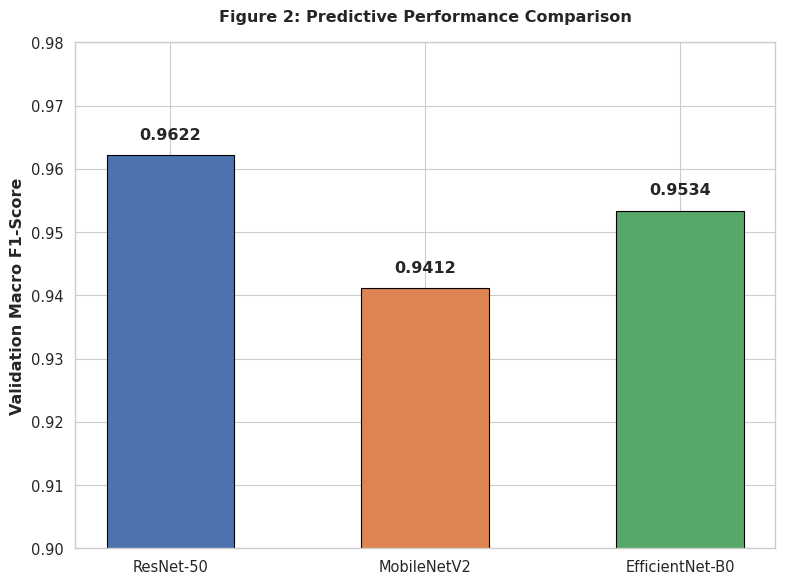

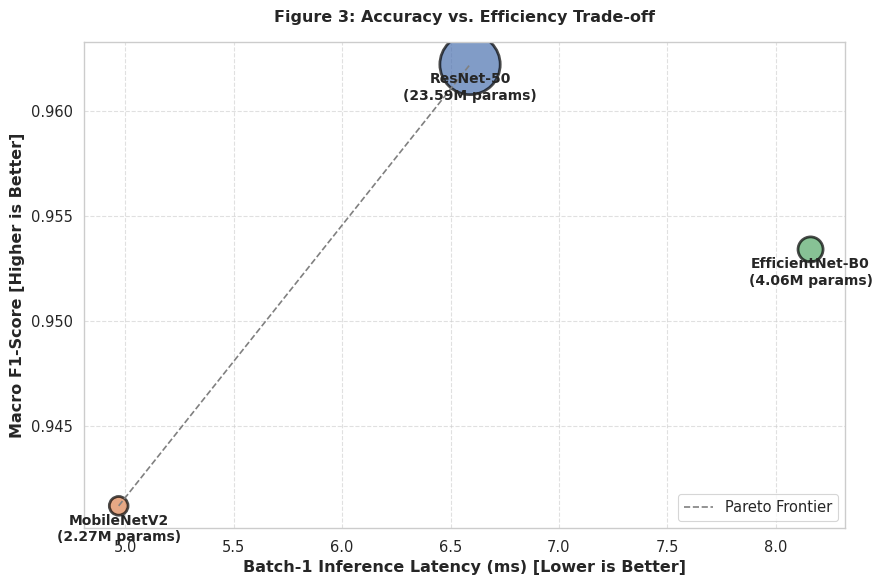


All visuals saved at 300 DPI directly to: /content/drive/MyDrive/AgriVision_Efficient_Research


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Set aesthetic style for academic publishing
sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)

# --- Data Arrays (from your terminal outputs) ---
model_names = ['ResNet-50', 'MobileNetV2', 'EfficientNet-B0']
macro_f1 = [0.9622, 0.9412, 0.9534]
latencies_ms = [6.59, 4.97, 8.16]
params_m = [23.59, 2.27, 4.06]

# ==========================================
# FIGURE 2: F1-Score Bar Comparison
# ==========================================
plt.figure(figsize=(8, 6))
colors = ['#4C72B0', '#DD8452', '#55A868']

bars = plt.bar(model_names, macro_f1, color=colors, width=0.5, edgecolor='black')
plt.ylim(0.90, 0.98) # Zoom in to show the 2% difference clearly
plt.ylabel('Validation Macro F1-Score', fontweight='bold')
plt.title('Figure 2: Predictive Performance Comparison', fontweight='bold', pad=15)

# Add exact numbers on top of bars
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.002, f"{yval:.4f}", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
fig2_path = f"{save_dir}/Figure_2_F1_Comparison.png"
plt.savefig(fig2_path, dpi=300, format='png', bbox_inches='tight')
plt.show()

# ==========================================
# FIGURE 3: Accuracy vs Latency Pareto Plot
# ==========================================
plt.figure(figsize=(9, 6))

# Create scatter plot where circle size = parameter count
scatter = plt.scatter(latencies_ms, macro_f1, s=[p * 80 for p in params_m],
                      c=colors, alpha=0.7, edgecolors="black", linewidth=2)

plt.xlabel('Batch-1 Inference Latency (ms) [Lower is Better]', fontweight='bold')
plt.ylabel('Macro F1-Score [Higher is Better]', fontweight='bold')
plt.title('Figure 3: Accuracy vs. Efficiency Trade-off', fontweight='bold', pad=15)

# Add labels next to bubbles
for i, name in enumerate(model_names):
    plt.annotate(f"{name}\n({params_m[i]}M params)",
                 (latencies_ms[i], macro_f1[i]),
                 textcoords="offset points",
                 xytext=(0,-25), ha='center', fontsize=10, fontweight='bold')

# Draw Pareto Frontier Line connecting MobileNetV2 and ResNet-50
pareto_x = [latencies_ms[1], latencies_ms[0]] # MobileNet to ResNet
pareto_y = [macro_f1[1], macro_f1[0]]
plt.plot(pareto_x, pareto_y, linestyle='--', color='gray', label='Pareto Frontier')

plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
fig3_path = f"{save_dir}/Figure_3_Pareto_Plot.png"
plt.savefig(fig3_path, dpi=300, format='png', bbox_inches='tight')
plt.show()

print(f"\nAll visuals saved at 300 DPI directly to: {save_dir}")